<a href="https://colab.research.google.com/github/afridajahan/periocular-deepfake-detection/blob/main/train_evaluate.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# ============================================================
# Cell 1: Mount Drive + imports
# ============================================================
from google.colab import drive
drive.mount('/content/drive')

import zipfile
import os
import json
import gc
import shutil
import psutil
import numpy as np
import cv2
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, models
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint
import matplotlib.pyplot as plt
from sklearn.metrics import (classification_report, confusion_matrix, roc_curve,
                              roc_auc_score, f1_score, precision_score, recall_score)
import seaborn as sns
from datetime import datetime
import time
import csv as _csv


class RAMLogger(keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        mem = psutil.virtual_memory()
        print(f"  [RAM] used={mem.used/1e9:.2f}GB / total={mem.total/1e9:.2f}GB "
              f"({mem.percent:.1f}%)")
        gc.collect()


keras.mixed_precision.set_global_policy('mixed_float16')

print("GPU available:", tf.config.list_physical_devices('GPU'))
print("Imports complete.")

# ============================================================
# CONFIGURATION - CHANGE SEED PER NOTEBOOK COPY, MODEL_NAME PER BACKBONE
# ============================================================
MODEL_NAME = "xception"   # <-- "xception" or "efficientnetb0"
SEED = 42                 # <-- CHANGE THIS: 42, then 123, then 2024 (one value per notebook run)

if MODEL_NAME == "xception":
    from tensorflow.keras.applications import Xception as BackboneClass
    from tensorflow.keras.applications.xception import preprocess_input
    IMG_HEIGHT, IMG_WIDTH = 160, 320
    LAST_CONV_LAYER_NAME = "block14_sepconv2_act"
elif MODEL_NAME == "efficientnetb0":
    from tensorflow.keras.applications import EfficientNetB0 as BackboneClass
    from tensorflow.keras.applications.efficientnet import preprocess_input
    IMG_HEIGHT, IMG_WIDTH = 112, 224
    LAST_CONV_LAYER_NAME = "top_activation"
else:
    raise ValueError("MODEL_NAME must be 'xception' or 'efficientnetb0'")

ZIP_PATH = f'/content/drive/MyDrive/roi_FDataset_rect_{IMG_HEIGHT}x{IMG_WIDTH}.zip'
MANIFEST_PATH = f'/content/drive/MyDrive/roi_FDataset_rect_{IMG_HEIGHT}x{IMG_WIDTH}_manifest.csv'

BATCH_SIZE = 32
EPOCHS_PHASE_1 = 20
EPOCHS_PHASE_2 = 20
MONITOR_METRIC = "val_auc"

BASE_CHECKPOINT_DIR = f'/content/drive/MyDrive/{MODEL_NAME}_checkpoints_{IMG_HEIGHT}x{IMG_WIDTH}'
os.makedirs(BASE_CHECKPOINT_DIR, exist_ok=True)

# SHARED across all 3 seed-notebooks
RESULTS_DIR = f'/content/drive/MyDrive/{MODEL_NAME}_seed_results_{IMG_HEIGHT}x{IMG_WIDTH}'
os.makedirs(RESULTS_DIR, exist_ok=True)

SOURCE_DIR = '/content/roi_source_extracted'
TRAIN_DIR = os.path.join(SOURCE_DIR, 'train')
VAL_DIR = os.path.join(SOURCE_DIR, 'validate')
TEST_DIR = os.path.join(SOURCE_DIR, 'test')


CACHE_DIR = f'/content/tfcache_{MODEL_NAME}_{IMG_HEIGHT}x{IMG_WIDTH}'
TRAIN_CACHE = os.path.join(CACHE_DIR, 'train_cache')
VAL_CACHE = os.path.join(CACHE_DIR, 'val_cache')
TEST_CACHE = os.path.join(CACHE_DIR, 'test_cache')

SHUFFLE_BUFFER = 4096
CACHE_BUILD_SEED = 42
os.makedirs(CACHE_DIR, exist_ok=True)
# ============================================================

if not os.path.exists(ZIP_PATH):
    raise FileNotFoundError(f"ZIP not found at {ZIP_PATH}")

# ---- Disk-space guard: warn BEFORE extracting if local disk looks tight ----
total, used, free = shutil.disk_usage("/content")
zip_size_gb = os.path.getsize(ZIP_PATH) / 1e9
print(f"Local disk free: {free/1e9:.1f} GB / {total/1e9:.1f} GB total")
print(f"Zip size: {zip_size_gb:.1f} GB")
if free / 1e9 < zip_size_gb * 4:
    print("WARNING: local disk may not comfortably fit extraction + tf.data caches "
          "for a dataset this size. Consider a smaller image size, TFRecords, or "
          "clearing CACHE_DIR/EXTRACT_TO between runs if you hit disk errors.")

if not os.path.exists(SOURCE_DIR):
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(SOURCE_DIR)
    print(f"Extracted to: {SOURCE_DIR}")
else:
    print(f"Already extracted at: {SOURCE_DIR} - skipping re-extract")

print(f"MODEL: {MODEL_NAME} | INPUT SIZE: {IMG_HEIGHT}x{IMG_WIDTH} | SEED: {SEED}")

Mounted at /content/drive
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Imports complete.
Local disk free: 70.8 GB / 120.9 GB total
Zip size: 1.7 GB
Extracted to: /content/roi_source_extracted
MODEL: xception | INPUT SIZE: 160x320 | SEED: 42


In [ ]:
# ============================================================
# Cell 2: Dataset is pre-split - just inventory it + leakage check
# ============================================================
print("\n" + "=" * 60)
print("DATASET INVENTORY (pre-split by extractor)")
print("=" * 60)


def list_images(folder):
    return [f for f in os.listdir(folder) if f.lower().endswith(('.jpg', '.jpeg', '.png'))]


split_files = {}
for split_name, split_dir in [('train', TRAIN_DIR), ('validate', VAL_DIR), ('test', TEST_DIR)]:
    split_files[split_name] = {}
    for label in ['real', 'fake']:
        folder = os.path.join(split_dir, label)
        split_files[split_name][label] = list_images(folder)
        print(f"  {split_name}/{label}: {len(split_files[split_name][label])} images")

n_real_train = len(split_files['train']['real'])
n_fake_train = len(split_files['train']['fake'])

# Rough estimate of on-disk cache size now that we know actual counts.
n_total_images = sum(len(split_files[s][l]) for s in split_files for l in ['real', 'fake'])
est_cache_gb = n_total_images * IMG_HEIGHT * IMG_WIDTH * 3 / 1e9
print(f"\nEstimated total disk cache size (train+val+test, uint8): ~{est_cache_gb:.1f} GB")

manifest = {}
if os.path.exists(MANIFEST_PATH):
    with open(MANIFEST_PATH) as f:
        reader = _csv.DictReader(f)
        for row in reader:
            manifest[row['filename']] = (row['label'], row['subtype'], row['group_id'])
    print(f"\nLoaded manifest with {len(manifest)} entries - checking for group leakage across splits")

    def groups_of(split_name):
        g = set()
        for label in ['real', 'fake']:
            for fname in split_files[split_name][label]:
                if fname in manifest:
                    g.add(manifest[fname][2])
        return g

    train_groups = groups_of('train')
    val_groups = groups_of('validate')
    test_groups = groups_of('test')

    overlap_tv = train_groups & val_groups
    overlap_tt = train_groups & test_groups
    overlap_vt = val_groups & test_groups

    if overlap_tv or overlap_tt or overlap_vt:
        print("WARNING: duplicate-hash groups span multiple splits:")
        print(f"  train<->validate overlap: {len(overlap_tv)} groups")
        print(f"  train<->test overlap:     {len(overlap_tt)} groups")
        print(f"  validate<->test overlap:  {len(overlap_vt)} groups")
    else:
        print("Confirmed: no near-duplicate group spans train/validate/test.")
else:
    print(f"\nNo manifest found at {MANIFEST_PATH} - skipping leakage check.")
    overlap_tv, overlap_tt, overlap_vt = set(), set(), set()


DATASET INVENTORY (pre-split by extractor)
  train/real: 41954 images
  train/fake: 30565 images
  validate/real: 13979 images
  validate/fake: 10189 images
  test/real: 13989 images
  test/fake: 10187 images

Estimated total disk cache size (train+val+test, uint8): ~18.6 GB

Loaded manifest with 120863 entries - checking for group leakage across splits
  train<->validate overlap: 12 groups
  train<->test overlap:     17 groups
  validate<->test overlap:  6 groups


In [ ]:
# ============================================================
# Cell 2b: Leakage cleanup - drop near-duplicate groups from TRAIN only
# ============================================================

if manifest and (overlap_tv or overlap_tt):
    print("\n" + "=" * 60)
    print("LEAKAGE CLEANUP: removing near-duplicate groups from TRAIN")
    print("=" * 60)

    leaking_group_ids = overlap_tv | overlap_tt
    removed = {'real': 0, 'fake': 0}

    for label in ['real', 'fake']:
        kept = []
        folder = os.path.join(TRAIN_DIR, label)
        for fname in split_files['train'][label]:
            group_id = manifest.get(fname, (None, None, None))[2]
            if group_id in leaking_group_ids:
                fpath = os.path.join(folder, fname)
                if os.path.exists(fpath):
                    os.remove(fpath)
                removed[label] += 1
            else:
                kept.append(fname)
        split_files['train'][label] = kept

    n_real_train = len(split_files['train']['real'])
    n_fake_train = len(split_files['train']['fake'])

    print(f"Removed from train: real={removed['real']}, fake={removed['fake']} "
          f"(across {len(leaking_group_ids)} leaking groups)")
    print(f"New train counts: real={n_real_train}, fake={n_fake_train}")
    print("validate/test were left untouched - only train was pruned.")
    print("\nNOTE: if you already built a tf.data disk cache in this runtime before "
          "running this cleanup, set CLEAR_CACHE_ON_START = True for this run so the "
          "stale (pre-cleanup) cache isn't silently reused.")
else:
    print("\nNo train-involving leakage to clean up - skipping Cell 2b.")


LEAKAGE CLEANUP: removing near-duplicate groups from TRAIN
Removed from train: real=9, fake=20 (across 29 leaking groups)
New train counts: real=41945, fake=30545
validate/test were left untouched - only train was pruned.

NOTE: if you already built a tf.data disk cache in this runtime before running this cleanup, set CLEAR_CACHE_ON_START = True for this run so the stale (pre-cleanup) cache isn't silently reused.


In [ ]:
# ============================================================
# Cell 3: Focal Loss (alpha auto-computed from train set balance)
# ============================================================
@tf.keras.utils.register_keras_serializable(package="custom_losses")
class FocalLoss(keras.losses.Loss):
    def __init__(self, gamma=2.0, alpha=0.5, name="focal_loss", **kwargs):
        super().__init__(name=name, **kwargs)
        self.gamma = gamma
        self.alpha = alpha

    def call(self, y_true, y_pred):
        y_true = tf.cast(y_true, tf.float32)
        y_pred = tf.cast(y_pred, tf.float32)
        epsilon = keras.backend.epsilon()
        y_pred = tf.clip_by_value(y_pred, epsilon, 1. - epsilon)
        pt = tf.where(tf.equal(y_true, 1), y_pred, 1 - y_pred)
        alpha_t = tf.where(tf.equal(y_true, 1), self.alpha, 1 - self.alpha)
        loss = -alpha_t * tf.pow(1 - pt, self.gamma) * tf.math.log(pt)
        return tf.reduce_mean(loss)

    def get_config(self):
        config = super().get_config()
        config.update({"gamma": self.gamma, "alpha": self.alpha})
        return config


FOCAL_ALPHA = n_real_train / (n_real_train + n_fake_train)
print(f"\nAuto-computed FOCAL_ALPHA = {FOCAL_ALPHA:.4f} "
      f"(train real={n_real_train}, fake={n_fake_train})")



Auto-computed FOCAL_ALPHA = 0.5786 (train real=41945, fake=30545)


In [ ]:
# ============================================================
# Cell 4: tf.data pipelines
# ============================================================
print("\n" + "=" * 60)
print("SETTING UP tf.data PIPELINES")
print("=" * 60)

AUTOTUNE = tf.data.AUTOTUNE


def make_dataset(directory, augment, seed, cache_path, shuffle_buffer=None,
                  need_file_paths=False, raw_shuffle=False):
    raw_ds = keras.utils.image_dataset_from_directory(
        directory,
        labels='inferred',
        label_mode='binary',
        class_names=['real', 'fake'],
        image_size=(IMG_HEIGHT, IMG_WIDTH),

        batch_size=None,
        shuffle=raw_shuffle,
        seed=CACHE_BUILD_SEED if raw_shuffle else None,
    )

    file_paths = raw_ds.file_paths if need_file_paths else None

    ds = raw_ds.map(lambda x, y: (tf.cast(x, tf.uint8), y), num_parallel_calls=AUTOTUNE)
    ds = ds.cache(cache_path)

    if shuffle_buffer:
        ds = ds.shuffle(buffer_size=shuffle_buffer, seed=seed, reshuffle_each_iteration=True)

    ds = ds.batch(BATCH_SIZE)

    if augment:
        aug_layers = keras.Sequential([
            layers.RandomFlip("horizontal"),
            layers.RandomZoom(0.1),
            layers.RandomBrightness(0.1),
        ])
        ds = ds.map(lambda x, y: (aug_layers(tf.cast(x, tf.float32), training=True), y),
                    num_parallel_calls=AUTOTUNE)
        ds = ds.map(lambda x, y: (preprocess_input(x), y), num_parallel_calls=AUTOTUNE)
    else:
        ds = ds.map(lambda x, y: (preprocess_input(tf.cast(x, tf.float32)), y),
                    num_parallel_calls=AUTOTUNE)

    ds = ds.prefetch(AUTOTUNE)
    return ds, file_paths


val_data, val_file_paths = make_dataset(VAL_DIR, augment=False, seed=42,
                                         cache_path=VAL_CACHE, need_file_paths=True)
test_data, test_file_paths = make_dataset(TEST_DIR, augment=False, seed=42,
                                           cache_path=TEST_CACHE, need_file_paths=True)

test_labels = np.concatenate([y.numpy() for _, y in test_data], axis=0).ravel()

train_data, _ = make_dataset(TRAIN_DIR, augment=True, seed=SEED,
                              cache_path=TRAIN_CACHE, shuffle_buffer=SHUFFLE_BUFFER,
                              raw_shuffle=True)

print("Class mapping: real=0, fake=1")


SETTING UP tf.data PIPELINES
Found 24168 files belonging to 2 classes.
Found 24176 files belonging to 2 classes.
Found 72490 files belonging to 2 classes.
Class mapping: real=0, fake=1


In [ ]:
# ============================================================
# Cell 5: Build model
# ============================================================
def build_model():
    base_model = BackboneClass(weights='imagenet', include_top=False,
                                input_shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    base_model.trainable = False

    inputs = keras.Input(shape=(IMG_HEIGHT, IMG_WIDTH, 3))
    x = base_model(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.BatchNormalization()(x)
    x = layers.Dense(256, activation='relu', kernel_regularizer=keras.regularizers.l2(0.01))(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation='sigmoid', dtype='float32')(x)
    model = keras.Model(inputs, outputs)
    return model, base_model

In [ ]:
# ============================================================
# Cell 6: Training (Phase 1 frozen + Phase 2 fine-tune) for THIS seed only
# ============================================================
print("\n" + "#" * 60)
print(f"# SEED {SEED}")
print("#" * 60)

tf.random.set_seed(SEED)
np.random.seed(SEED)

seed_ckpt_dir = os.path.join(BASE_CHECKPOINT_DIR, f"seed_{SEED}")
os.makedirs(seed_ckpt_dir, exist_ok=True)
phase1_ckpt = os.path.join(seed_ckpt_dir, 'phase1_best.keras')
phase2_ckpt = os.path.join(seed_ckpt_dir, 'phase2_best.keras')
state_json = os.path.join(seed_ckpt_dir, 'training_state.json')


def load_state():
    if os.path.exists(state_json):
        with open(state_json) as f:
            return json.load(f)
    return {"phase1_done": False, "phase2_done": False}


def save_state(state):
    with open(state_json, 'w') as f:
        json.dump(state, f, indent=2)


state = load_state()

model, base_model = build_model()
model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss=FocalLoss(gamma=2.0, alpha=FOCAL_ALPHA),
    metrics=['accuracy', keras.metrics.AUC(name='auc')]
)

# ---------------- Phase 1: frozen backbone ----------------

time_phase1 = 0.0
history_phase1 = None

if os.path.exists(phase1_ckpt):
    print("Found phase1 checkpoint - loading as starting weights.")
    model = keras.models.load_model(phase1_ckpt)
    base_model = model.layers[1]

if state["phase1_done"]:
    print("Phase 1 already marked complete - skipping training.")
else:
    start = time.time()
    callbacks_phase1 = [
        EarlyStopping(patience=5, restore_best_weights=True, monitor=MONITOR_METRIC, mode='max'),
        ReduceLROnPlateau(patience=3, factor=0.5, monitor=MONITOR_METRIC, mode='max', min_lr=1e-7),
        ModelCheckpoint(phase1_ckpt, save_best_only=True, monitor=MONITOR_METRIC, mode='max'),
        RAMLogger()
    ]
    history_phase1 = model.fit(
        train_data, validation_data=val_data,
        epochs=EPOCHS_PHASE_1, callbacks=callbacks_phase1, verbose=2
    )
    time_phase1 = time.time() - start
    state["phase1_done"] = True
    save_state(state)
    print(f"Phase 1 took {time_phase1/60:.2f} min, "
          f"best {MONITOR_METRIC}={max(history_phase1.history[MONITOR_METRIC]):.4f}")

# ---------------- Phase 2: fine-tune ----------------
time_phase2 = 0.0
history_phase2 = None

if os.path.exists(phase2_ckpt):
    print("Found phase2 checkpoint - loading as starting weights.")
    model = keras.models.load_model(phase2_ckpt)
    base_model = model.layers[1]

if state["phase2_done"]:
    print("Phase 2 already marked complete - skipping training.")
else:
    base_model.trainable = True
    n_layers = len(base_model.layers)
    freeze_cutoff = int(n_layers * 0.8)

    for i, layer in enumerate(base_model.layers):
        if i < freeze_cutoff or isinstance(layer, layers.BatchNormalization):
            layer.trainable = False
        else:
            layer.trainable = True

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=1e-5),
        loss=FocalLoss(gamma=2.0, alpha=FOCAL_ALPHA),
        metrics=['accuracy', keras.metrics.AUC(name='auc')]
    )

    start = time.time()
    callbacks_phase2 = [
        EarlyStopping(patience=4, restore_best_weights=True, monitor=MONITOR_METRIC, mode='max'),
        ReduceLROnPlateau(patience=2, factor=0.5, monitor=MONITOR_METRIC, mode='max', min_lr=1e-8),
        ModelCheckpoint(phase2_ckpt, save_best_only=True, monitor=MONITOR_METRIC, mode='max'),
        RAMLogger()
    ]
    history_phase2 = model.fit(
        train_data, validation_data=val_data,
        epochs=EPOCHS_PHASE_2, callbacks=callbacks_phase2, verbose=2
    )
    time_phase2 = time.time() - start
    state["phase2_done"] = True
    save_state(state)
    print(f"Phase 2 took {time_phase2/60:.2f} min, "
          f"best {MONITOR_METRIC}={max(history_phase2.history[MONITOR_METRIC]):.4f}")



############################################################
# SEED 42
############################################################
83683744/83683744 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Found phase1 checkpoint - loading as starting weights.
Epoch 1/20
  [RAM] used=4.09GB / total=13.61GB (33.0%)
2266/2266 - 903s - 399ms/step - accuracy: 0.7330 - auc: 0.7997 - loss: 0.0812 - val_accuracy: 0.7543 - val_auc: 0.8218 - val_loss: 0.0779 - learning_rate: 0.0010
Epoch 2/20
  [RAM] used=5.75GB / total=13.61GB (45.2%)
2266/2266 - 663s - 293ms/step - accuracy: 0.7413 - auc: 0.8090 - loss: 0.0786 - val_accuracy: 0.7634 - val_auc: 0.8335 - val_loss: 0.0759 - learning_rate: 0.0010
Epoch 3/20
  [RAM] used=6.57GB / total=13.61GB (51.3%)
2266/2266 - 660s - 291ms/step - accuracy: 0.7458 - auc: 0.8148 - loss: 0.0763 - val_accuracy: 0.7663 - val_auc: 0.8413 - val_loss: 0.0721 - learning_rate: 0.0010
Epoch 4/20
  [RAM] used=6.86GB / total=13.61GB (53.4%)
2266/2266 - 682s - 301ms/step - accuracy: 0.7499 - auc:

In [ ]:
# ============================================================
# Cell 7: Threshold selection on VAL, then TEST evaluation
# ============================================================
val_labels = np.concatenate([y.numpy() for _, y in val_data], axis=0).ravel()
val_proba = model.predict(val_data, verbose=0).ravel()
fpr_val, tpr_val, thresholds_val = roc_curve(val_labels, val_proba)
best_threshold = float(thresholds_val[np.argmax(tpr_val - fpr_val)])

test_proba = model.predict(test_data, verbose=0).ravel()
test_pred = (test_proba > best_threshold).astype(int)

metrics = {
    'seed': SEED,
    'threshold': best_threshold,
    'test_accuracy': float((test_pred == test_labels).mean()),
    'test_auc': float(roc_auc_score(test_labels, test_proba)),
    'f1_macro': float(f1_score(test_labels, test_pred, average='macro')),
    'f1_weighted': float(f1_score(test_labels, test_pred, average='weighted')),
    'f1_fake': float(f1_score(test_labels, test_pred, pos_label=1)),
    'precision_fake': float(precision_score(test_labels, test_pred, pos_label=1)),
    'recall_fake': float(recall_score(test_labels, test_pred, pos_label=1)),
    'phase1_time_min': time_phase1 / 60,
    'phase2_time_min': time_phase2 / 60,
    'focal_loss_alpha': FOCAL_ALPHA,
    'monitor_metric': MONITOR_METRIC,
    'model': MODEL_NAME,
    'input_height': IMG_HEIGHT,
    'input_width': IMG_WIDTH,
}

final_model_path = os.path.join(seed_ckpt_dir, f'{MODEL_NAME}_periocular_seed{SEED}_final.keras')
model.save(final_model_path)
metrics['model_path'] = final_model_path

print(f"\nSeed {SEED} TEST results: acc={metrics['test_accuracy']*100:.2f}%, "
      f"AUC={metrics['test_auc']:.4f}, F1(fake)={metrics['f1_fake']:.4f}")

seed_result_path = os.path.join(RESULTS_DIR, f'{MODEL_NAME}_seed{SEED}_metrics.json')
with open(seed_result_path, 'w') as f:
    json.dump(metrics, f, indent=2)
print(f"Saved this seed's results to: {seed_result_path}")
print(f"Once all 3 seeds are done, run aggregate_seed_results.py pointed at: {RESULTS_DIR}")



Seed 42 TEST results: acc=96.34%, AUC=0.9926, F1(fake)=0.9564
Saved this seed's results to: /content/drive/MyDrive/xception_seed_results_160x320/xception_seed42_metrics.json
Once all 3 seeds are done, run aggregate_seed_results.py pointed at: /content/drive/MyDrive/xception_seed_results_160x320


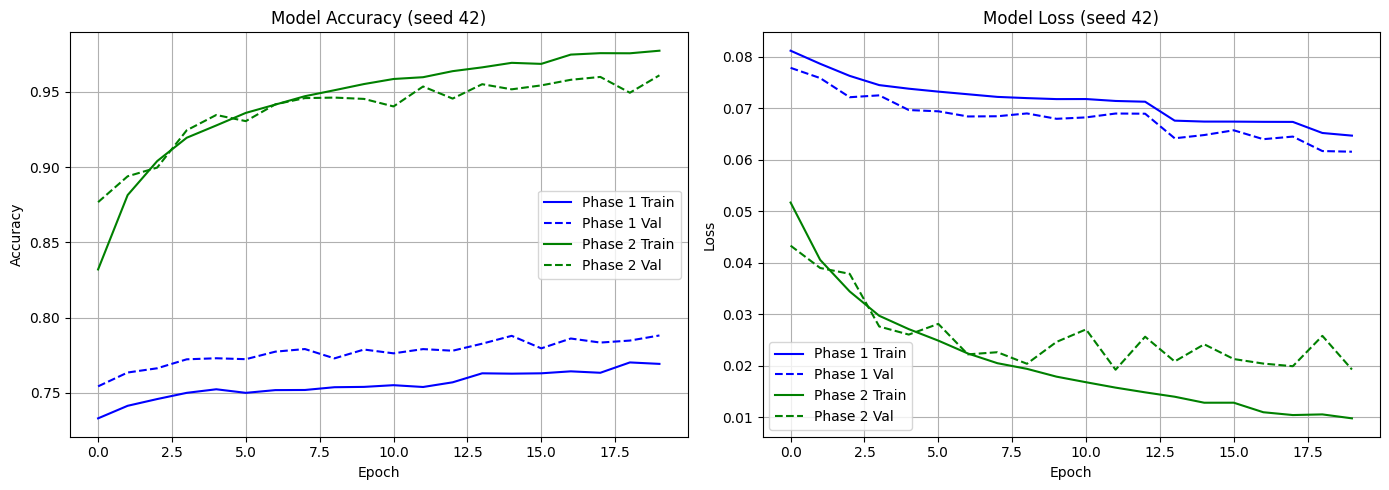

In [ ]:
# ============================================================
# Cell 8: Training curves (this seed)
# ============================================================
if history_phase1 is not None and history_phase2 is not None:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    axes[0].plot(history_phase1.history['accuracy'], label='Phase 1 Train', color='blue')
    axes[0].plot(history_phase1.history['val_accuracy'], label='Phase 1 Val', color='blue', linestyle='--')
    axes[0].plot(history_phase2.history['accuracy'], label='Phase 2 Train', color='green')
    axes[0].plot(history_phase2.history['val_accuracy'], label='Phase 2 Val', color='green', linestyle='--')
    axes[0].set_title(f'Model Accuracy (seed {SEED})'); axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Accuracy')
    axes[0].legend(); axes[0].grid(True)

    axes[1].plot(history_phase1.history['loss'], label='Phase 1 Train', color='blue')
    axes[1].plot(history_phase1.history['val_loss'], label='Phase 1 Val', color='blue', linestyle='--')
    axes[1].plot(history_phase2.history['loss'], label='Phase 2 Train', color='green')
    axes[1].plot(history_phase2.history['val_loss'], label='Phase 2 Val', color='green', linestyle='--')
    axes[1].set_title(f'Model Loss (seed {SEED})'); axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Loss')
    axes[1].legend(); axes[1].grid(True)
    plt.tight_layout(); plt.show()
else:
    print("Skipping training curves - this seed was loaded entirely from checkpoint.")



CLASSIFICATION REPORT (seed 42, threshold=0.363):
              precision    recall  f1-score   support

        REAL       0.96      0.97      0.97     13989
        FAKE       0.96      0.95      0.96     10187

    accuracy                           0.96     24176
   macro avg       0.96      0.96      0.96     24176
weighted avg       0.96      0.96      0.96     24176



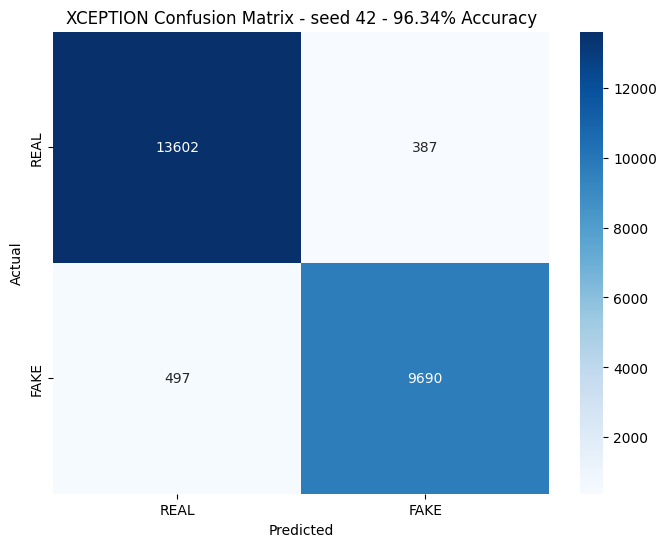

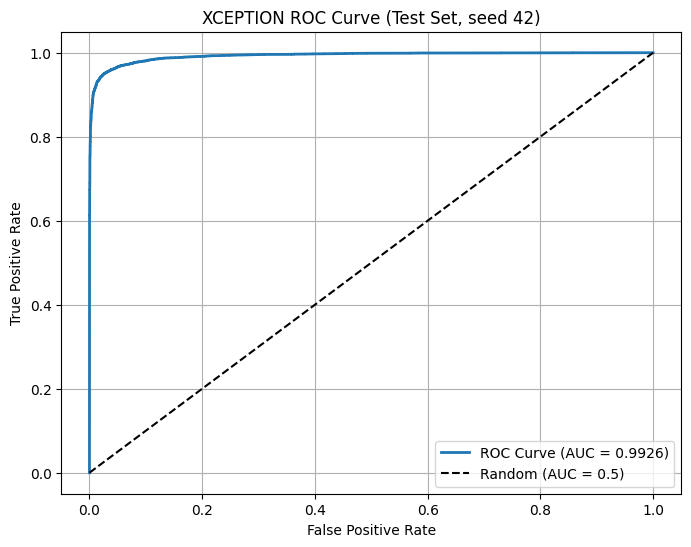

In [ ]:
# ============================================================
# Cell 9: Confusion matrix + ROC (this seed)
# ============================================================
print(f"\nCLASSIFICATION REPORT (seed {SEED}, threshold={best_threshold:.3f}):")
print(classification_report(test_labels, test_pred, target_names=['REAL', 'FAKE']))

cm = confusion_matrix(test_labels, test_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['REAL', 'FAKE'], yticklabels=['REAL', 'FAKE'])
plt.xlabel('Predicted'); plt.ylabel('Actual')
plt.title(f'{MODEL_NAME.upper()} Confusion Matrix - seed {SEED} - '
          f'{metrics["test_accuracy"]*100:.2f}% Accuracy')
plt.show()

fpr, tpr, _ = roc_curve(test_labels, test_proba)
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, linewidth=2, label=f'ROC Curve (AUC = {metrics["test_auc"]:.4f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random (AUC = 0.5)')
plt.xlabel('False Positive Rate'); plt.ylabel('True Positive Rate')
plt.title(f'{MODEL_NAME.upper()} ROC Curve (Test Set, seed {SEED})')
plt.legend(); plt.grid(True); plt.show()


In [ ]:
# ============================================================
# Cell 10: Grad-CAM implementation
# ============================================================
def make_gradcam_heatmap(img_array, model, base_model, last_conv_layer_name):
    last_conv_layer = base_model.get_layer(last_conv_layer_name)

    conv_model = keras.Model(base_model.input, [last_conv_layer.output, base_model.output])

    base_model_index = model.layers.index(base_model)
    head_layers = model.layers[base_model_index + 1:]

    with tf.GradientTape() as tape:
        conv_output, base_output = conv_model(img_array, training=False)
        tape.watch(conv_output)
        x = base_output
        for layer in head_layers:
            x = layer(x, training=False)
        preds = tf.cast(x, tf.float32)
        loss = preds[:, 0]

    grads = tape.gradient(loss, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_output = conv_output[0]
    heatmap = conv_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy().astype(np.float32)


def load_and_preprocess_single(filepath):
    img = keras.utils.load_img(filepath, target_size=(IMG_HEIGHT, IMG_WIDTH))
    arr = keras.utils.img_to_array(img)
    batch = np.expand_dims(arr, axis=0)
    return preprocess_input(batch.copy()), arr.astype(np.uint8)


def overlay_heatmap(orig_img_uint8, heatmap, alpha=0.4):
    h, w = orig_img_uint8.shape[:2]
    heatmap_resized = cv2.resize(heatmap, (w, h))
    heatmap_uint8 = np.uint8(255 * heatmap_resized)
    heatmap_color = cv2.applyColorMap(heatmap_uint8, cv2.COLORMAP_JET)
    heatmap_color = cv2.cvtColor(heatmap_color, cv2.COLOR_BGR2RGB)
    overlay = np.uint8(orig_img_uint8 * (1 - alpha) + heatmap_color * alpha)
    return overlay


def show_gradcam_grid(filepaths, titles, ncols=4, figsize_per=(3.2, 3.6)):
    n = len(filepaths)
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(figsize_per[0]*ncols, figsize_per[1]*nrows))
    axes = np.array(axes).reshape(-1)
    for i, (fp, title) in enumerate(zip(filepaths, titles)):
        batch, orig = load_and_preprocess_single(fp)
        heatmap = make_gradcam_heatmap(batch, model, base_model, LAST_CONV_LAYER_NAME)
        overlay = overlay_heatmap(orig, heatmap)
        axes[i].imshow(overlay)
        axes[i].set_title(title, fontsize=8)
        axes[i].axis('off')
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')
    plt.tight_layout()
    plt.show()



GRAD-CAM SANITY CHECK (random correct + incorrect test samples)


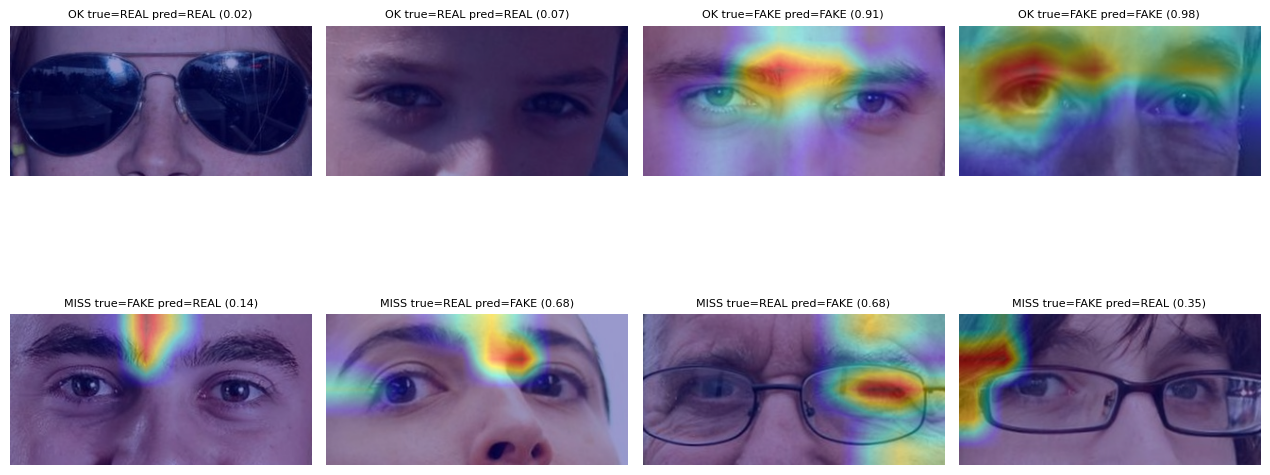

In [ ]:
# ============================================================
# Cell 11: Grad-CAM sanity check on a random dataset sample
# ============================================================
print("\n" + "=" * 60)
print("GRAD-CAM SANITY CHECK (random correct + incorrect test samples)")
print("=" * 60)

rng = np.random.default_rng(42)
correct_mask = (test_pred == test_labels)
incorrect_mask = ~correct_mask

sample_correct_idx = rng.choice(np.where(correct_mask)[0], size=min(4, correct_mask.sum()), replace=False)
sample_incorrect_idx = rng.choice(np.where(incorrect_mask)[0], size=min(4, incorrect_mask.sum()), replace=False)
sample_idx = np.concatenate([sample_correct_idx, sample_incorrect_idx])

sample_paths = [test_file_paths[i] for i in sample_idx]
sample_titles = [
    f"{'OK' if correct_mask[i] else 'MISS'} true={'FAKE' if test_labels[i]==1 else 'REAL'} "
    f"pred={'FAKE' if test_pred[i]==1 else 'REAL'} ({test_proba[i]:.2f})"
    for i in sample_idx
]
show_gradcam_grid(sample_paths, sample_titles)


QUALITATIVE FAILURE ANALYSIS (top-confidence errors)
Found 387 false positives, 497 false negatives in test set (showing top 8 / 8 most confident errors).

--- Top False Positives (REAL misclassified as FAKE) ---


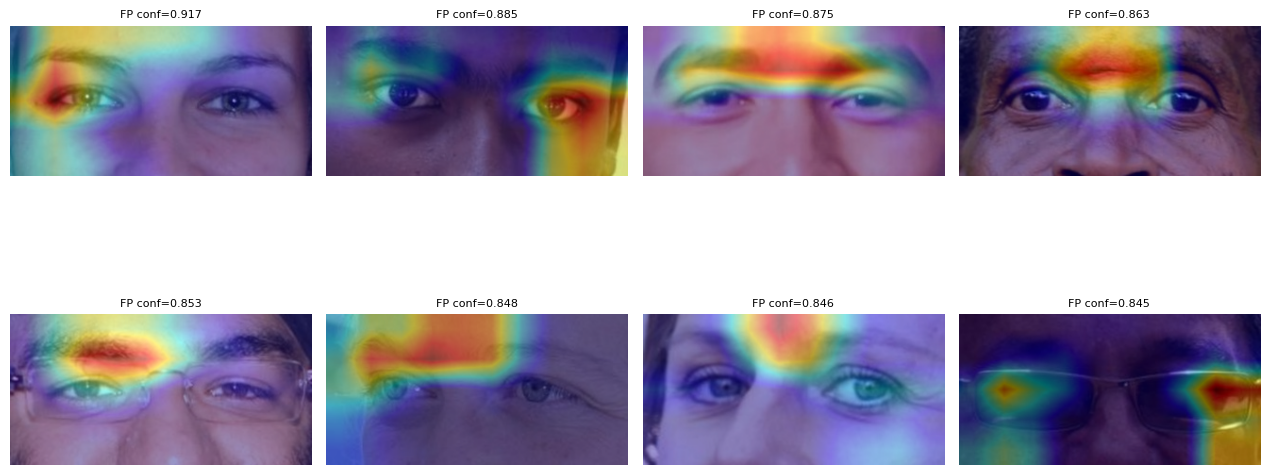


--- Top False Negatives (FAKE misclassified as REAL) ---


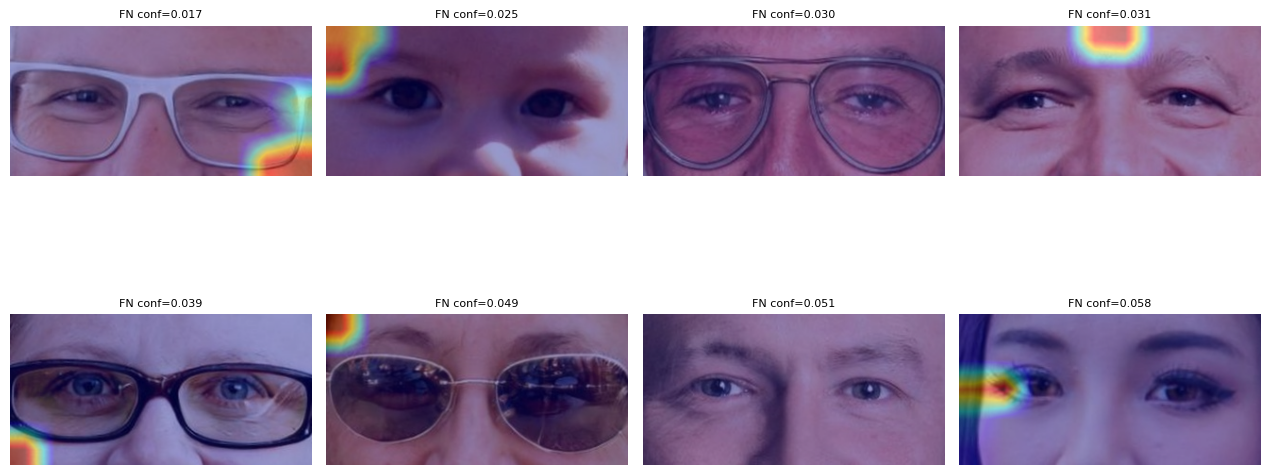


Done with seed 42. All artifacts saved to Drive:
  This seed's metrics JSON: /content/drive/MyDrive/xception_seed_results_160x320/xception_seed42_metrics.json
  This seed's final model: /content/drive/MyDrive/xception_checkpoints_160x320/seed_42/xception_periocular_seed42_final.keras
  Checkpoints:             /content/drive/MyDrive/xception_checkpoints_160x320/seed_42

Next: change SEED at the top and re-run for the remaining seeds, then run aggregate_seed_results.py once all 3 are in /content/drive/MyDrive/xception_seed_results_160x320


In [ ]:
# ============================================================
# Cell 12: Qualitative failure analysis - top FP / FN by confidence + Grad-CAM
# ============================================================
print("\n" + "=" * 60)
print("QUALITATIVE FAILURE ANALYSIS (top-confidence errors)")
print("=" * 60)

fp_idx = np.where((test_labels == 0) & (test_pred == 1))[0]
fp_ranked = fp_idx[np.argsort(-test_proba[fp_idx])][:8]

fn_idx = np.where((test_labels == 1) & (test_pred == 0))[0]
fn_ranked = fn_idx[np.argsort(test_proba[fn_idx])][:8]

print(f"Found {len(fp_idx)} false positives, {len(fn_idx)} false negatives in test set "
      f"(showing top {len(fp_ranked)} / {len(fn_ranked)} most confident errors).")

if len(fp_ranked) > 0:
    print("\n--- Top False Positives (REAL misclassified as FAKE) ---")
    fp_paths = [test_file_paths[i] for i in fp_ranked]
    fp_titles = [f"FP conf={test_proba[i]:.3f}" for i in fp_ranked]
    show_gradcam_grid(fp_paths, fp_titles)
else:
    print("No false positives found.")

if len(fn_ranked) > 0:
    print("\n--- Top False Negatives (FAKE misclassified as REAL) ---")
    fn_paths = [test_file_paths[i] for i in fn_ranked]
    fn_titles = [f"FN conf={test_proba[i]:.3f}" for i in fn_ranked]
    show_gradcam_grid(fn_paths, fn_titles)
else:
    print("No false negatives found.")

print(f"\nDone with seed {SEED}. All artifacts saved to Drive:")
print(f"  This seed's metrics JSON: {seed_result_path}")
print(f"  This seed's final model: {final_model_path}")
print(f"  Checkpoints:             {seed_ckpt_dir}")
print(f"\nNext: change SEED at the top and re-run for the remaining seeds, then run "
      f"aggregate_seed_results.py once all 3 are in {RESULTS_DIR}")